# Scaling with the number of qubits

Loads the committed results (`results/`) and plots AUC as the register grows (6 → 16 qubits), one bar per step count L, with the classical baseline as a dashed line. Same layout as the photonic benchmark slide.

*Quantum bars use only the readout features above their own shot noise (denoised), as in the report table.*

In [1]:
import matplotlib.pyplot as plt, numpy as np
from iontraps_qrc.report import load_grid, compare_with_report, REPO
df = load_grid()
FIG = REPO / "figures"; FIG.mkdir(exist_ok=True)
df[["qubits","L","sup_q","sup_c","sup_diff","sup_lo","sup_hi","zd_q","zd_c","zd_diff","zd_lo","zd_hi","feats_live","feats"]].round(3)

,qubits,L,sup_q,sup_c,sup_diff,sup_lo,sup_hi,zd_q,zd_c,zd_diff,zd_lo,zd_hi,feats_live,feats
0,6,6,0.965,0.984,-0.018,-0.032,-0.008,0.867,0.888,-0.021,-0.048,0.006,21,24
1,6,8,0.975,0.985,-0.010,-0.025,0.001,0.859,0.888,-0.029,-0.047,-0.013,27,30
2,6,10,0.980,0.986,-0.006,-0.019,0.003,0.878,0.888,-0.010,-0.023,0.003,31,36
3,8,6,0.977,0.985,-0.008,-0.020,0.002,0.864,0.888,-0.024,-0.045,-0.005,26,32
4,8,8,0.979,0.986,-0.008,-0.015,-0.001,0.871,0.888,-0.016,-0.035,-0.000,34,40
5,8,10,0.984,0.986,-0.003,-0.014,0.005,0.883,0.888,-0.004,-0.019,0.009,41,48
6,10,6,0.984,0.986,-0.002,-0.010,0.005,0.882,0.888,-0.005,-0.018,0.007,34,40
7,10,8,0.976,0.986,-0.011,-0.028,0.003,0.875,0.888,-0.012,-0.024,-0.002,43,50
8,10,10,0.984,0.986,-0.002,-0.008,0.003,0.882,0.888,-0.006,-0.020,0.006,52,60
9,12,6,0.962,0.986,-0.024,-0.044,-0.008,0.861,0.888,-0.026,-0.048,-0.005,36,48


## Check against the report table
Every cell, rounded to 3 decimals, must equal the table in the report.

In [2]:
chk = compare_with_report(df)
print(f"{chk.match.sum()}/{len(chk)} cells match the report table")
assert chk.match.all(), chk[~chk.match]

18/18 cells match the report table


## Figure 1 — AUC vs number of qubits

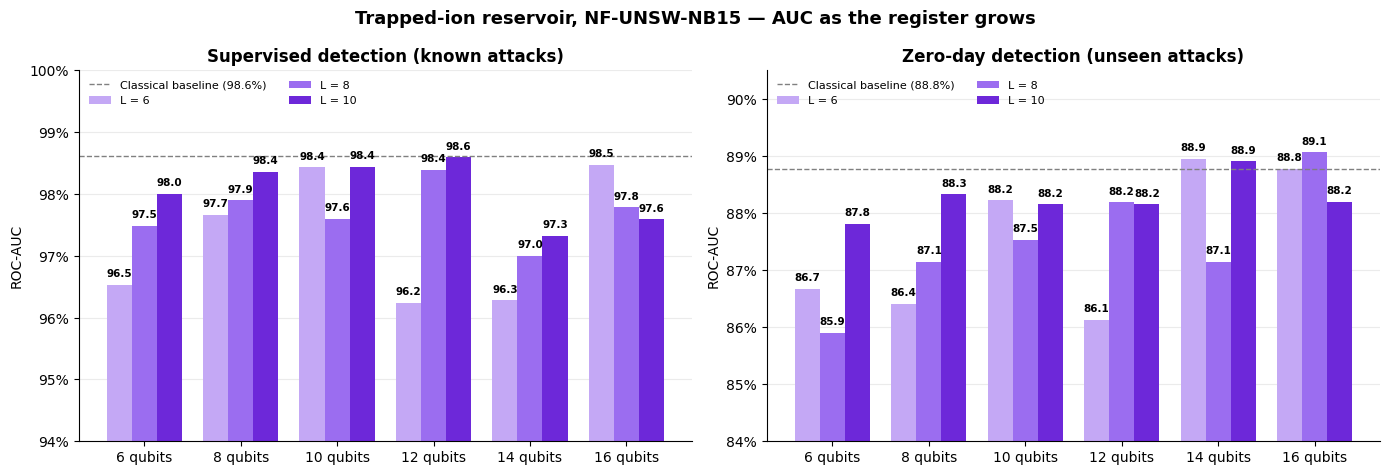

In [3]:
COLORS = {6: "#c4a8f5", 8: "#9b6df0", 10: "#6d28d9"}
Ls = sorted(df.L.unique()); Ns = sorted(df.qubits.unique())

def panel(ax, q, c, title, ylabel, ylim):
    w = 0.26
    for i, L in enumerate(Ls):
        sub = df[df.L == L].set_index("qubits").loc[Ns]
        x = np.arange(len(Ns)) + (i - 1) * w
        bars = ax.bar(x, sub[q], w, color=COLORS[L], label=f"L = {L}")
        for b, v in zip(bars, sub[q]):
            ax.text(b.get_x() + b.get_width()/2, v + 0.0008*(ylim[1]-ylim[0])/0.05, f"{100*v:.1f}",
                    ha="center", va="bottom", fontsize=7.5, fontweight="bold")
    base = df[c].mean()
    ax.axhline(base, ls="--", color="gray", lw=1, label=f"Classical baseline ({100*base:.1f}%)")
    ax.set_xticks(range(len(Ns))); ax.set_xticklabels([f"{n} qubits" for n in Ns])
    ax.set_ylim(*ylim); ax.set_ylabel(ylabel); ax.set_title(title, fontweight="bold")
    ax.yaxis.set_major_formatter(lambda v, _: f"{100*v:.0f}%" if abs(100*v-round(100*v))<1e-9 else f"{100*v:.1f}%")
    for s in ("top","right"): ax.spines[s].set_visible(False)
    ax.grid(axis="y", alpha=.25); ax.set_axisbelow(True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
panel(axes[0], "sup_q", "sup_c", "Supervised detection (known attacks)", "ROC-AUC", (0.94, 1.0))
panel(axes[1], "zd_q", "zd_c", "Zero-day detection (unseen attacks)", "ROC-AUC", (0.84, 0.905))
for a_ in axes: a_.legend(loc="upper left", frameon=False, ncol=2, fontsize=8)
fig.suptitle("Trapped-ion reservoir, NF-UNSW-NB15 — AUC as the register grows", fontsize=13, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "auc_vs_qubits.png", dpi=200); fig.savefig(FIG / "auc_vs_qubits.pdf"); plt.show()

## Figure 2 — gap to the classical baseline (quantum − classical, 95% interval)
Negative = reservoir is behind. An interval wholly below zero is a significant deficit.

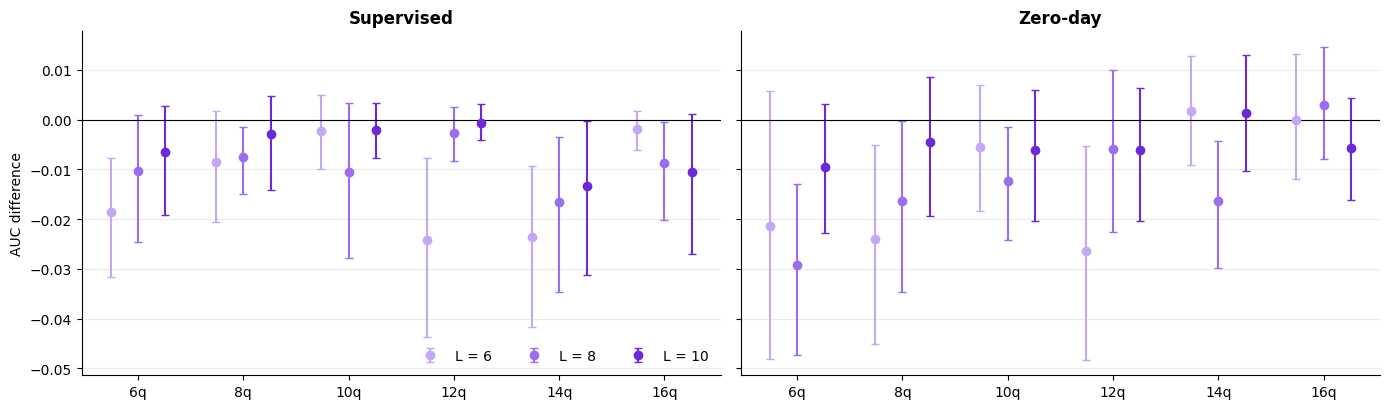

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, k, title in ((axes[0], "sup", "Supervised"), (axes[1], "zd", "Zero-day")):
    for i, L in enumerate(Ls):
        s = df[df.L == L].set_index("qubits").loc[Ns]; x = np.arange(len(Ns)) + (i-1)*0.26
        ax.errorbar(x, s[f"{k}_diff"], yerr=[s[f"{k}_diff"]-s[f"{k}_lo"], s[f"{k}_hi"]-s[f"{k}_diff"]],
                    fmt="o", color=COLORS[L], capsize=3, label=f"L = {L}")
    ax.axhline(0, color="k", lw=.8); ax.set_xticks(range(len(Ns))); ax.set_xticklabels([f"{n}q" for n in Ns])
    ax.set_title(title, fontweight="bold"); ax.grid(axis="y", alpha=.25)
    for s_ in ("top","right"): ax.spines[s_].set_visible(False)
axes[0].set_ylabel("AUC difference"); axes[0].legend(frameon=False, ncol=3, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "gap_vs_qubits.png", dpi=200); plt.show()

## Figure 3 — live readout features
Features above their own shot noise, out of those measured.

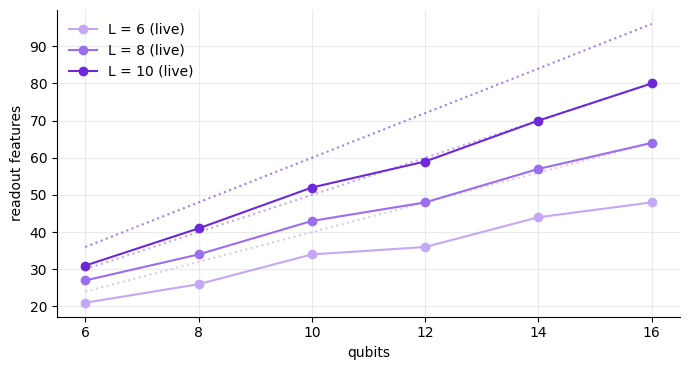

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for L in Ls:
    s = df[df.L == L].set_index("qubits").loc[Ns]
    ax.plot(Ns, s.feats_live, "o-", color=COLORS[L], label=f"L = {L} (live)")
    ax.plot(Ns, s.feats, ":", color=COLORS[L], alpha=.6)
ax.set_xlabel("qubits"); ax.set_ylabel("readout features"); ax.legend(frameon=False); ax.grid(alpha=.25)
for s_ in ("top","right"): ax.spines[s_].set_visible(False)
fig.tight_layout(); fig.savefig(FIG / "live_features_vs_qubits.png", dpi=200); plt.show()